In [7]:
import sys

print(sys.executable)

c:\Users\USER\anaconda3\envs\rpk-env\python.exe


In [8]:
import sys

!{sys.executable} -m pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 2.8 MB/s eta 0:00:04
   --- ------------------------------------ 1.0/11.3 MB 3.4 MB/s eta 0:00:04
   ----- ---------------------------------- 1.6/11.3 MB 2.7 MB/s eta 0:00:04
   ------- -------------------------------- 2.1/11.3 MB 2.7 MB/s eta 0:00:04
   ---------- ----------------------------- 2.9/11.3 MB 2.8 MB/s eta 0:00:04
   ------------- -------------------------- 3.9/11.3 MB 3.0 MB/s eta 0:00:03
   --------------- ------------------------ 4.5/11.3 MB 2.9 MB/s eta 0:00:03
   ------------------ --------------------- 5.2/11.3 MB 3.0 MB/s eta 0:00:03
   --------------------- ------------------ 6.0/11.3 MB 3.1 MB/s eta 0:00:02
   --------------------- ------------------ 6.0/11.3 MB 3.1 MB/s eta 0:00:02
   ----------------------- ---------------- 6.6/11.3 MB 2.8 MB/s eta 0:00:02
   ------------------------- -------------- 7.1/11.3 MB 2.7 MB/s eta 0:00:02
   ---

In [9]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf

warnings.filterwarnings("ignore")

In [12]:
# komoditas yang akan dianalisis
KOMODITAS = [
    "Cabe Merah Kriting",
    "Bawang Merah (Kualitas Lokal)",
    "Beras Premium",
]

df = pd.read_csv(
    "C:/Users/USER/Downloads/harga_komoditas.csv",
    encoding="utf-8-sig",
    parse_dates=["tanggal"]
)
df.head()

,tanggal,komoditas,satuan,harga
0,2023-01-01,Air Mineral (Aqua Galon),19 Ltr/Galon,18000.00000
1,2023-01-01,Bawang Bombay,Kg,21714.28571
2,2023-01-01,Bawang Merah (Kualitas Lokal),Kg,31857.14286
3,2023-01-01,Bawang Putih (Jenis Kating),Kg,26714.28571
4,2023-01-01,Bawang Putih (Jenis Sinco),Kg,23000.00000


In [13]:
def ambil_series(nama):
    s = (
        df[df["komoditas"] == nama]
        .set_index("tanggal")["harga"]
        .sort_index()
    )

    return s.asfreq("D").interpolate()

Mengambil data harga berdasarkan nama komoditas yang akan dianalisis. Data kemudian diurutkan berdasarkan tanggal agar tersusun secara kronologis. Selanjutnya, frekuensi data disesuaikan menjadi harian (daily). Apabila terdapat tanggal yang tidak memiliki data, nilai yang kosong akan diisi menggunakan metode interpolasi. Tahapan ini dilakukan agar data memiliki interval waktu yang teratur sehingga dapat digunakan dalam analisis deret waktu (time series).

In [14]:
def uji_stasioner(s):
    s = s.dropna()

    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]

    return adf_p, kpss_p

Untuk mengetahui apakah data harga komoditas telah memenuhi asumsi stasioneritas atau belum. Pengujian dilakukan menggunakan dua metode, yaitu Augmented Dickey-Fuller (ADF) dan Kwiatkowski-Phillips-Schmidt-Shin (KPSS). Metode ADF memiliki hipotesis nol bahwa data tidak stasioner, sedangkan KPSS memiliki hipotesis nol bahwa data bersifat stasioner. Penggunaan kedua metode tersebut bertujuan untuk memperoleh hasil pengujian yang lebih menyeluruh dalam menentukan kondisi stasioneritas data. Hasil pengujian ditentukan berdasarkan nilai p-value dengan tingkat signifikansi sebesar 5%.

In [15]:
def label(adf_p, kpss_p):
    # ADF: H0 = tidak stasioner
    # KPSS: H0 = stasioner

    return (
        "Stasioner"
        if (adf_p < 0.05 and kpss_p > 0.05)
        else "Tidak stasioner"
    )

Menentukan kesimpulan dari hasil pengujian ADF dan KPSS. Data dinyatakan stasioner apabila nilai p-value ADF kurang dari 0,05 dan nilai p-value KPSS lebih dari 0,05. Sebaliknya, apabila salah satu kriteria tersebut tidak terpenuhi, data dikategorikan belum stasioner.

Tahapan ini membantu menentukan apakah data harga komoditas masih memerlukan proses transformasi, seperti differencing, sebelum digunakan dalam pemodelan SARIMA.

In [16]:
def plot_nonstasioner(nama):

    s = ambil_series(nama)
    ds = s.diff().dropna()

    # Uji stasioneritas
    adf0, kpss0 = uji_stasioner(s)
    adf1, kpss1 = uji_stasioner(ds)

    fig, ax = plt.subplots(2, 3, figsize=(18, 9))

    fig.suptitle(
        f"Uji Kestasioneran: {nama}",
        fontsize=15,
        fontweight="bold"
    )

    # 1. Harga dan rata-rata bergerak
    ax[0, 0].plot(
        s, color="tab:blue", lw=1, label="Harga"
    )

    ax[0, 0].plot(
        s.rolling(90).mean(),
        color="tab:red",
        lw=2,
        label="Rata-rata 90 hari"
    )

    ax[0, 0].set_title(
        "Harga & rata-rata bergerak"
    )
    ax[0, 0].legend()

    # 2. Simpangan baku bergerak
    ax[0, 1].plot(
        s.rolling(90).std(),
        color="tab:orange",
        lw=2
    )

    ax[0, 1].set_title(
        "Simpangan baku bergerak 90 hari"
    )

    # 3. ACF data asli
    plot_acf(s, lags=60, ax=ax[0, 2])

    ax[0, 2].set_title(
        "ACF data asli"
    )

    # 4. Differencing orde 1
    ax[1, 0].plot(
        ds,
        color="tab:green",
        lw=0.8
    )

    ax[1, 0].axhline(
        0,
        color="black",
        lw=0.8
    )

    ax[1, 0].set_title(
        "Setelah differencing orde 1"
    )

    # 5. ACF setelah differencing
    plot_acf(ds, lags=60, ax=ax[1, 1])

    ax[1, 1].set_title(
        "ACF setelah differencing"
    )

    # 6. Ringkasan uji formal
    ax[1, 2].axis("off")

    teks = (
        "HASIL UJI FORMAL\n\n"
        "Data asli:\n"
        f"  ADF p-value  = {adf0:.4f}\n"
        f"  KPSS p-value = {kpss0:.4f}\n"
        f"  Kesimpulan   : {label(adf0, kpss0)}\n\n"
        "Setelah differencing (d=1):\n"
        f"  ADF p-value  = {adf1:.4f}\n"
        f"  KPSS p-value = {kpss1:.4f}\n"
        f"  Kesimpulan   : {label(adf1, kpss1)}\n\n"
        "ADF: H0 = tidak stasioner\n"
        "KPSS: H0 = stasioner"
    )

    ax[1, 2].text(
        0,
        0.95,
        teks,
        va="top",
        family="monospace",
        fontsize=11
    )

    plt.tight_layout()

    # Menyimpan gambar
    plt.savefig(
        f"stasioneritas_{nama.split()[0].lower()}.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    return {
        "Komoditas": nama,
        "ADF p (asli)": round(adf0, 4),
        "KPSS p (asli)": round(kpss0, 4),
        "Kesimpulan (asli)": label(adf0, kpss0),
        "ADF p (diff)": round(adf1, 4),
        "KPSS p (diff)": round(kpss1, 4),
        "Kesimpulan (diff)": label(adf1, kpss1)
    }

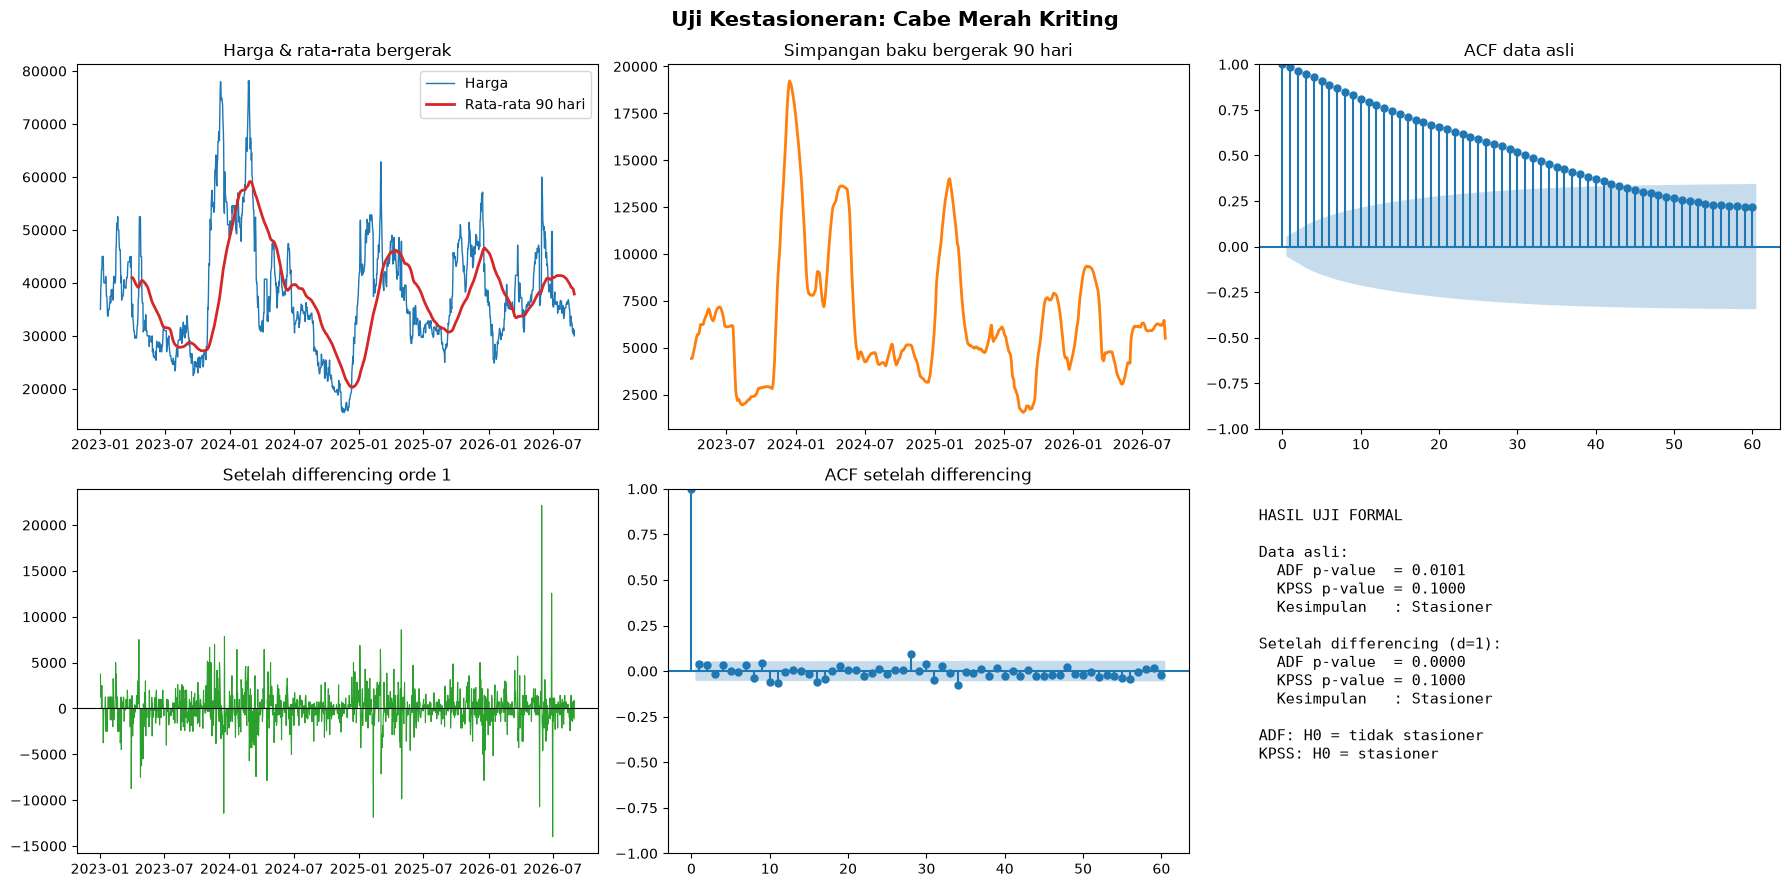

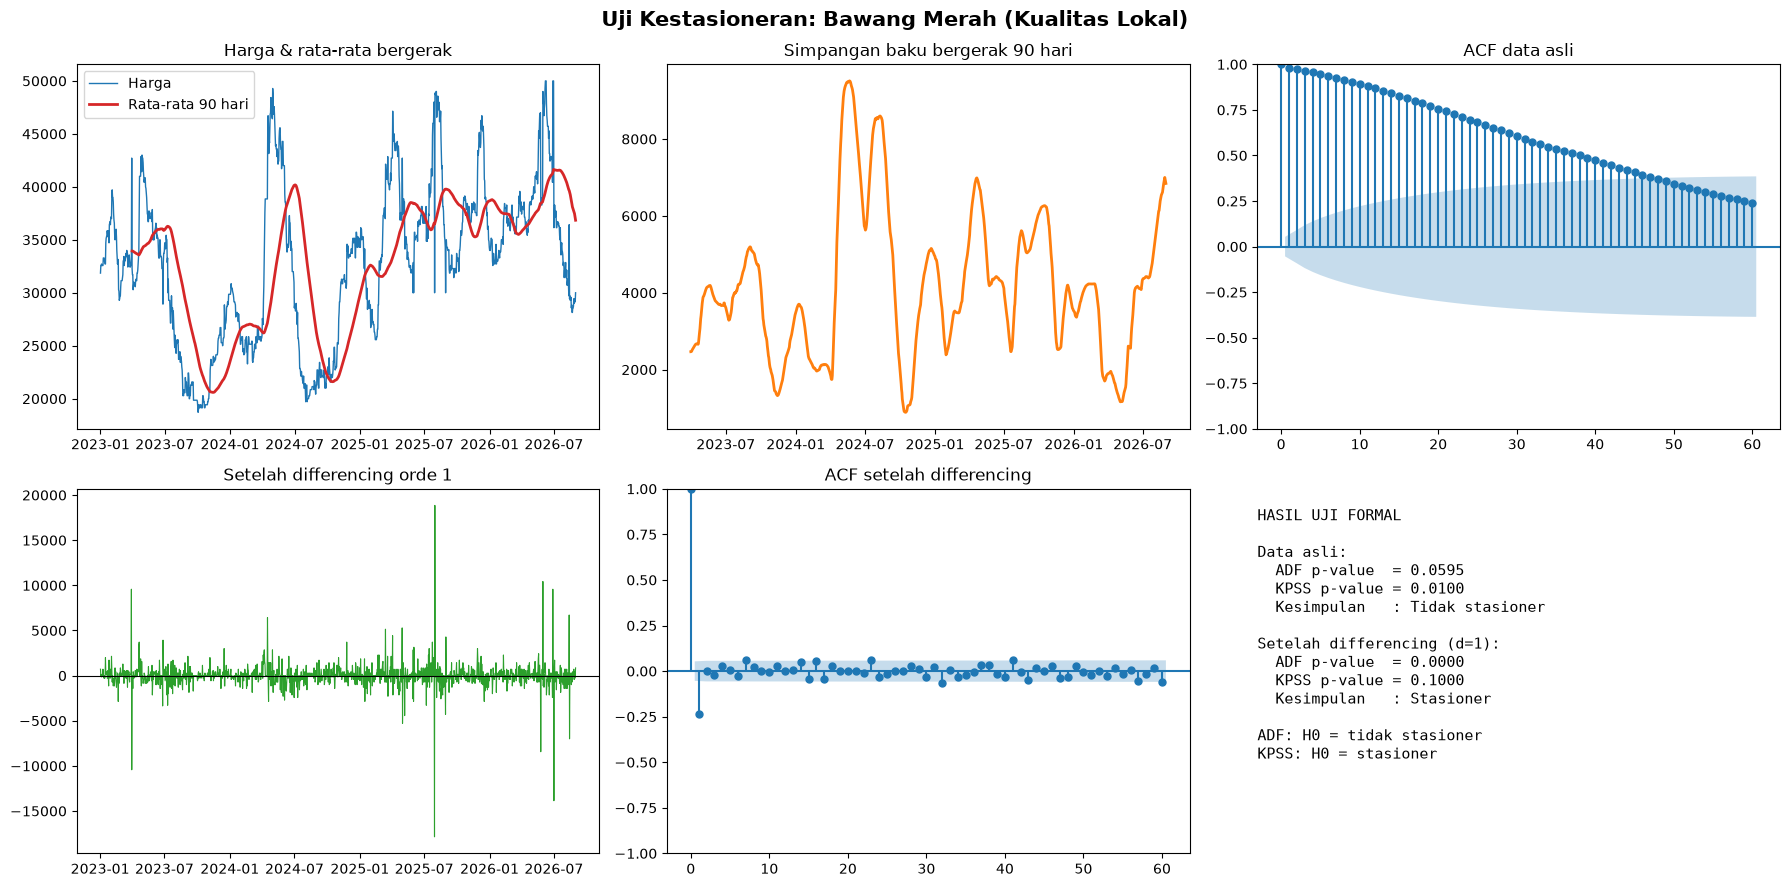

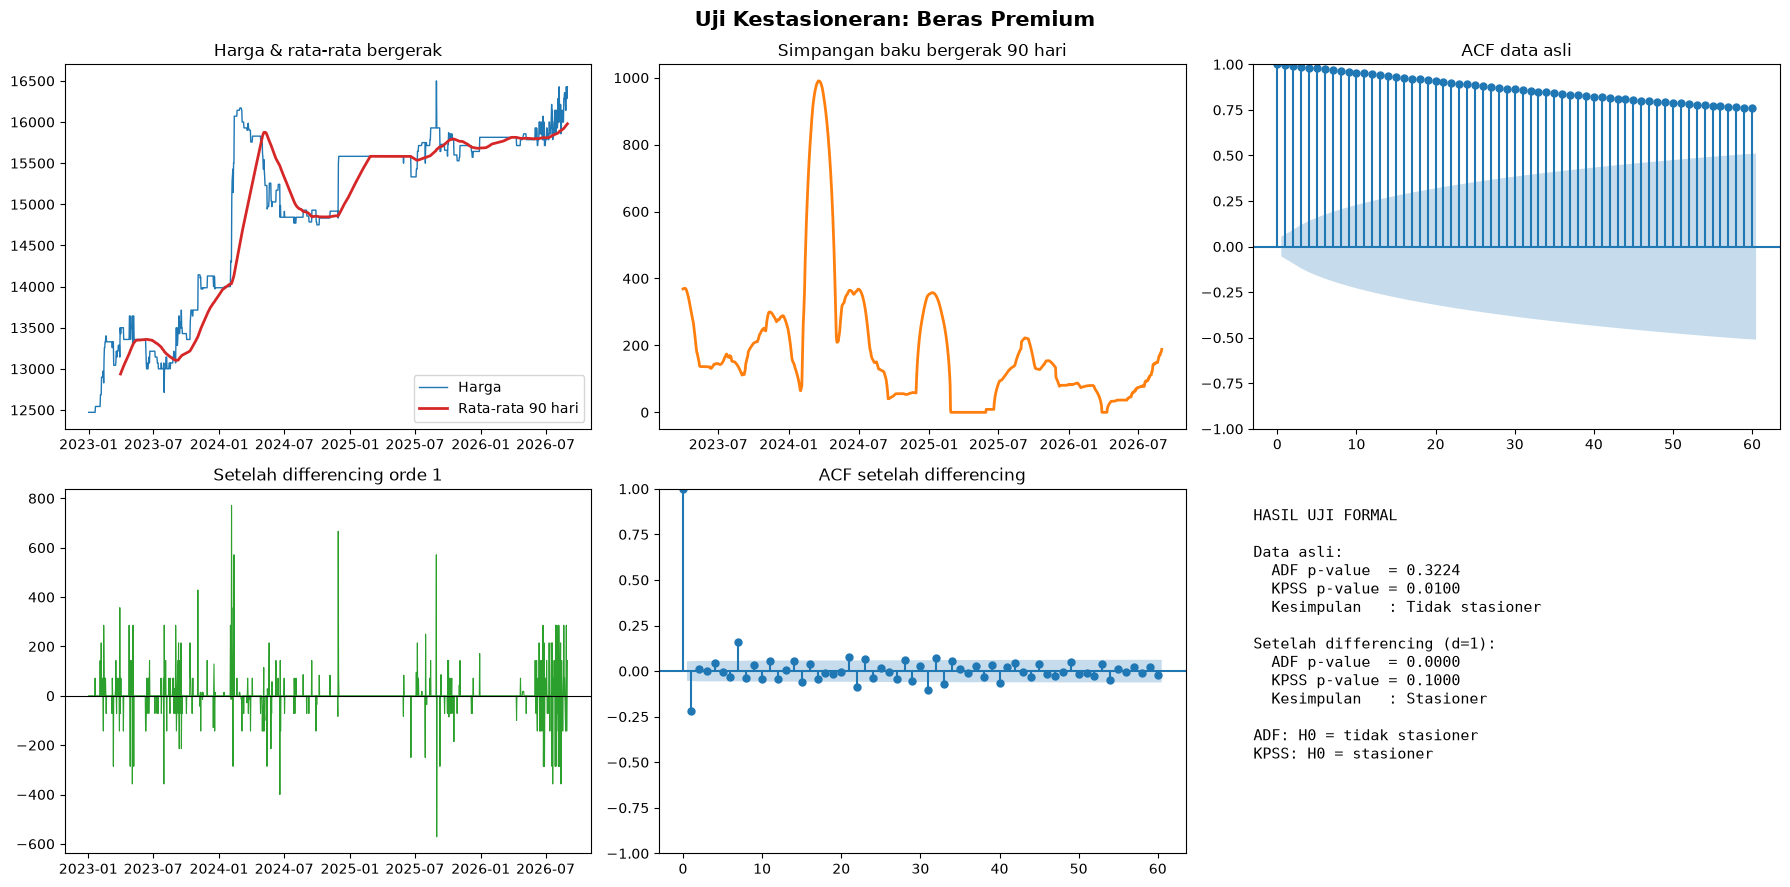

In [17]:
ringkasan = pd.DataFrame([
    plot_nonstasioner(k)
    for k in KOMODITAS
])

Berdasarkan hasil pengujian ADF dan KPSS, data harga Cabai Merah Keriting menunjukkan kondisi stasioner pada data asli. Hal ini ditunjukkan oleh nilai p-value ADF sebesar 0,0101 yang lebih kecil dari 0,05 dan nilai p-value KPSS sebesar 0,1000 yang lebih besar dari 0,05.

Hasil tersebut menunjukkan bahwa data telah memenuhi kriteria stasioneritas berdasarkan kedua pengujian. Setelah dilakukan differencing orde 1, data juga menunjukkan kondisi stasioner. Dengan demikian, berdasarkan pengujian formal, data harga Cabai Merah Keriting tidak memerlukan differencing untuk memenuhi asumsi stasioneritas.

Hasil pengujian pada data asli menunjukkan bahwa harga Beras Premium belum memenuhi asumsi stasioneritas. Hal ini ditunjukkan oleh nilai p-value ADF sebesar 0,3224 yang lebih besar dari 0,05 serta nilai p-value KPSS sebesar 0,0100 yang lebih kecil dari 0,05.

Setelah dilakukan differencing orde 1, nilai p-value ADF berubah menjadi 0,0000, sedangkan nilai p-value KPSS sebesar 0,1000. Hasil tersebut menunjukkan bahwa data telah memenuhi kriteria stasioneritas setelah differencing. Dengan demikian, differencing orde 1 dapat digunakan untuk mengatasi ketidakstasioneran pada data harga Beras Premium.

Berdasarkan hasil pengujian stasioneritas terhadap tiga komoditas pangan, diketahui bahwa masing-masing komoditas memiliki karakteristik deret waktu yang berbeda. Harga Cabai Merah Keriting telah memenuhi kriteria stasioneritas berdasarkan pengujian ADF dan KPSS pada data asli. Sementara itu, harga Bawang Merah dan Beras Premium belum stasioner pada data asli, tetapi telah menjadi stasioner setelah dilakukan differencing orde 1.

Hasil ini menunjukkan bahwa tidak semua komoditas memerlukan perlakuan differencing yang sama. Oleh karena itu, pengujian stasioneritas menjadi salah satu tahapan penting sebelum melakukan pemodelan SARIMA. Hasil pengujian ini juga dapat digunakan sebagai pertimbangan awal dalam menentukan orde differencing pada masing-masing komoditas.

In [18]:
print("RINGKASAN HASIL UJI STASIONERITAS")

display(ringkasan)

RINGKASAN HASIL UJI STASIONERITAS


,Komoditas,ADF p (asli),KPSS p (asli),Kesimpulan (asli),ADF p (diff),KPSS p (diff),Kesimpulan (diff)
0,Cabe Merah Kriting,0.0101,0.10,Stasioner,0.0,0.1,Stasioner
1,Bawang Merah (Kualitas Lokal),0.0595,0.01,Tidak stasioner,0.0,0.1,Stasioner
2,Beras Premium,0.3224,0.01,Tidak stasioner,0.0,0.1,Stasioner
